<a href="https://colab.research.google.com/github/marufacoder/job_1_python/blob/main/test_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

7. Import the Titanic dataset (titanic.csv) into the Python environment using Pandas.
8. Perform data cleaning by retaining only the survived, sex, age, fare, and pclass columns, and
remove all rows containing missing values

Task 1 — Data Loading and Preparation
We will load the Titanic dataset, filter it to the selected columns (survived, sex, age, fare, pclass), drop rows containing missing values, and print the shape and the first 5 rows.


In [ ]:
import pandas as pd
import numpy as np
# Load the Titanic dataset
url = '/content/drive/MyDrive/dataset_2026/Taitanic.csv'
df_raw = pd.read_csv(url)

# Keep only the requested columns
columns_to_keep = ['Survived', 'Sex', 'Age', 'Fare', 'Pclass']
df = df_raw[columns_to_keep].copy()

# Standardize column names to lowercase for consistency
df.columns = df.columns.str.lower()

# Drop rows with missing values
df_clean = df.dropna()

# Display shape and first 5 rows
print(f"DataFrame Shape after dropping missing values: {df_clean.shape}\n")
display(df_clean.head())

DataFrame Shape after dropping missing values: (714, 5)



,survived,sex,age,fare,pclass
0,0,male,22.0,7.2500,3
1,1,female,38.0,71.2833,1
2,1,female,26.0,7.9250,3
3,1,female,35.0,53.1000,1
4,0,male,35.0,8.0500,3


9. Calculate the mean, median, and mode of the age and fare columns to measure central tendency.
10. Determine the variance, standard deviation, and range of the age and fare columns to analyses
data dispersion.
# Task 2 & Task 3 — Central Tendency and Measures of Dispersion
We will calculate and display statistics for both age and fare:

Central Tendency: Mean, Median, Mode
Dispersion: Variance, Standard Deviation, Range

In [ ]:
# Helper function to calculate and print statistics
def compute_statistics(df, col_name):
    # Central Tendency
    mean_val = df[col_name].mean()
    median_val = df[col_name].median()
    mode_val = df[col_name].mode()[0]  # Mode can return multiple values, we take the first

    # Measures of Dispersion
    var_val = df[col_name].var()
    std_val = df[col_name].std()
    range_val = df[col_name].max() - df[col_name].min()

    print(f"--- Statistics for '{col_name.upper()}' ---")
    print(f"Mean:               {mean_val:.4f}")
    print(f"Median:             {median_val:.4f}")
    print(f"Mode:               {mode_val:.4f}")
    print(f"Variance:           {var_val:.4f}")
    print(f"Standard Deviation: {std_val:.4f}")
    print(f"Range:              {range_val:.4f}\n")

compute_statistics(df_clean, 'age')
compute_statistics(df_clean, 'fare')

--- Statistics for 'AGE' ---
Mean:               29.6991
Median:             28.0000
Mode:               24.0000
Variance:           211.0191
Standard Deviation: 14.5265
Range:              79.5800

--- Statistics for 'FARE' ---
Mean:               34.6945
Median:             15.7417
Mode:               13.0000
Variance:           2800.4131
Standard Deviation: 52.9189
Range:              512.3292



11. Create a correlation matrix using the survived, age, fare, and pclass variables

Task 4 — Correlation Analysis
We will compute the Pearson correlation matrix for survived, age, fare, and pclass to see how these numerical features relate to one another.

In [ ]:
# Calculate the correlation matrix
corr_cols = ['survived', 'age', 'fare', 'pclass']
correlation_matrix = df_clean[corr_cols].corr()

print("--- Correlation Matrix ---")
display(correlation_matrix)

# Unstack the matrix to find and sort the unique correlation pairs
corr_pairs = correlation_matrix.unstack()
sorted_pairs = corr_pairs.sort_values(kind="quicksort", ascending=False)

# Filter out self-correlations (correlation of 1.0 with itself)
unique_pairs = sorted_pairs[sorted_pairs < 1.0]

# Since the matrix is symmetric, we get duplicates (e.g., A-B and B-A). Take every other item.
strongest = unique_pairs.iloc[::2]

print("\n--- Top Correlation Pairs (by absolute value) ---")
for (var1, var2), coef in strongest.abs().sort_values(ascending=False).items():
    actual_coef = unique_pairs[(var1, var2)]
    print(f"{var1} vs {var2}: {actual_coef:.4f}")

--- Correlation Matrix ---


,survived,age,fare,pclass
survived,1.000000,-0.077221,0.268189,-0.359653
age,-0.077221,1.000000,0.096067,-0.369226
fare,0.268189,0.096067,1.000000,-0.554182
pclass,-0.359653,-0.369226,-0.554182,1.000000



--- Top Correlation Pairs (by absolute value) ---
fare vs pclass: -0.5542
age vs pclass: -0.3692
pclass vs survived: -0.3597
survived vs fare: 0.2682
fare vs age: 0.0961
survived vs age: -0.0772


New Chapter Begin Titanic Dataset Part 2 KDE

# Task 1 — Data Loading and Preparation

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Try to load the dataset from common paths or seaborn's built-in datasets
try:
    df = pd.read_csv('titanic.csv')
except FileNotFoundError:
    # Fallback to seaborn's online dataset if local file is not found
    df = sns.load_dataset('titanic')

# Keep specified columns
columns_to_keep = ['survived', 'pclass', 'sex', 'age', 'fare']
df = df[columns_to_keep]

# Drop missing rows
df = df.dropna()

# Display shape and first 5 rows
print(f"Dataset Shape: {df.shape}")
display(df.head())

Dataset Shape: (714, 5)


,survived,pclass,sex,age,fare
0,0,3,male,22.0,7.2500
1,1,1,female,38.0,71.2833
2,1,3,female,26.0,7.9250
3,1,1,female,35.0,53.1000
4,0,3,male,35.0,8.0500


Task 2 — Survival Report

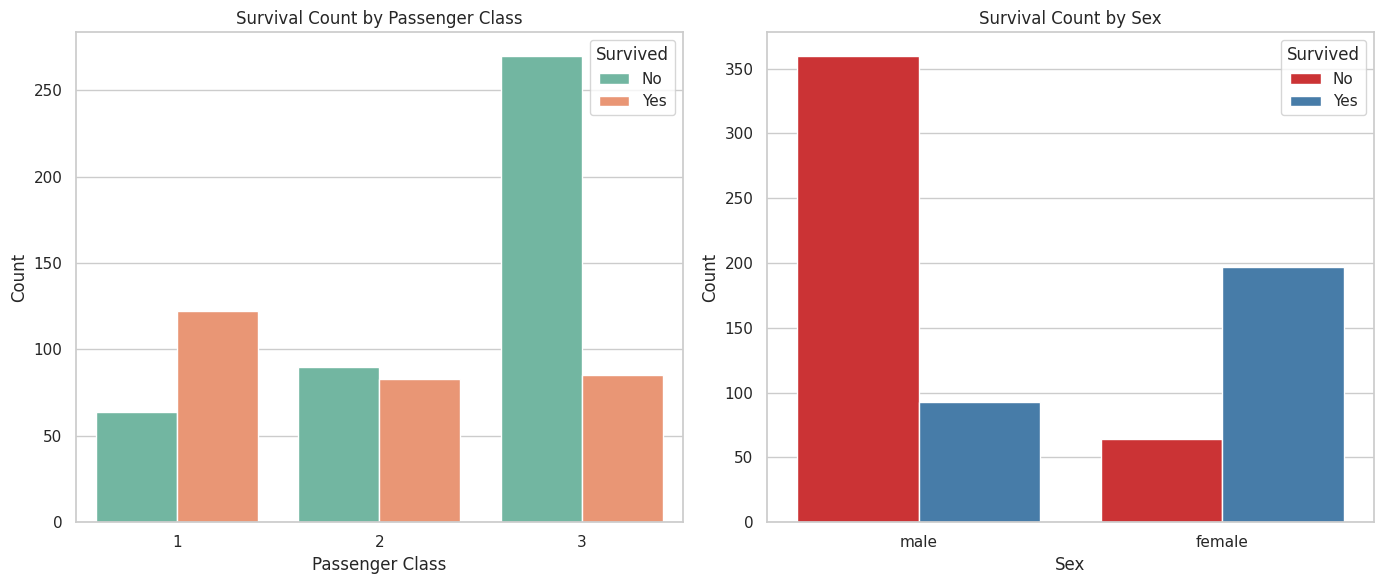

In [ ]:
# Set up the plotting style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Survival count by passenger class
sns.countplot(data=df, x='pclass', hue='survived', ax=axes[0], palette='Set2')
axes[0].set_title('Survival Count by Passenger Class')
axes[0].set_xlabel('Passenger Class')
axes[0].set_ylabel('Count')
axes[0].legend(title='Survived', labels=['No', 'Yes'])

# Survival count by sex
sns.countplot(data=df, x='sex', hue='survived', ax=axes[1], palette='Set1')
axes[1].set_title('Survival Count by Sex')
axes[1].set_xlabel('Sex')
axes[1].set_ylabel('Count')
axes[1].legend(title='Survived', labels=['No', 'Yes'])

plt.tight_layout()
plt.show()

Task 3 — Distribution of Age

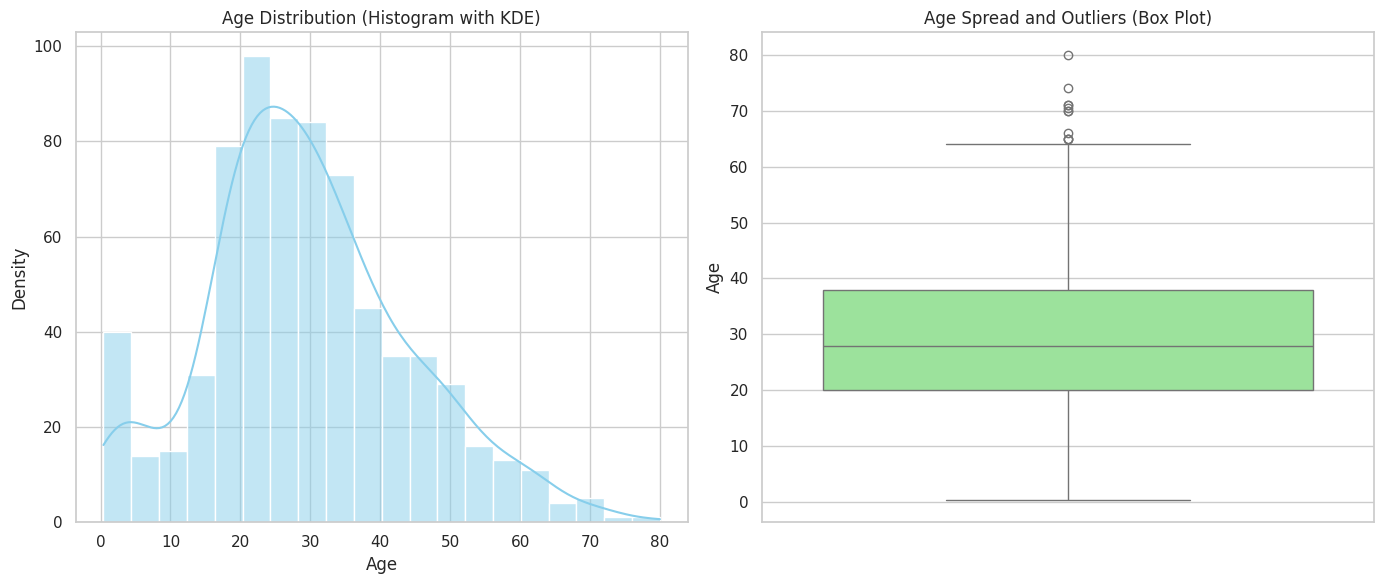

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Histogram with KDE
sns.histplot(data=df, x='age', kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Age Distribution (Histogram with KDE)')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Density')

# Box plot
sns.boxplot(data=df, y='age', ax=axes[1], color='lightgreen')
axes[1].set_title('Age Spread and Outliers (Box Plot)')
axes[1].set_ylabel('Age')

plt.tight_layout()
plt.show()

Task 4 — Correlation Heatmap

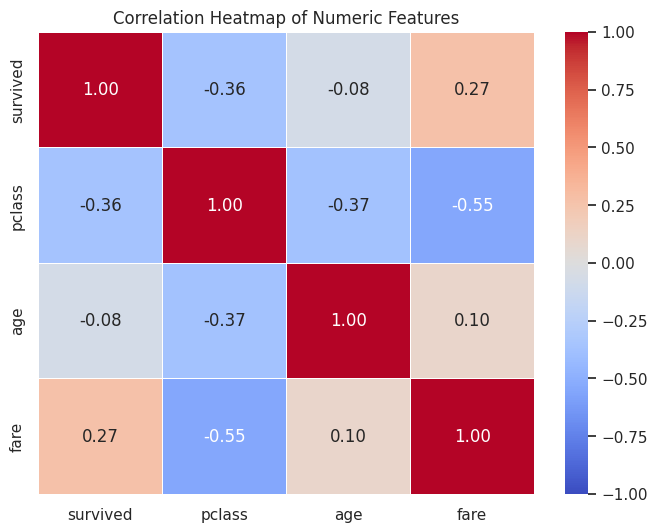

Strongest Positive Correlation: survived and fare (0.27)
Strongest Negative Correlation: pclass and fare (-0.55)


In [ ]:
import numpy as np

# Keep only numeric columns for correlation
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()

# Set up the matplotlib figure
plt.figure(figsize=(8, 6))

# Draw the heatmap with annotations
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Numeric Features')
plt.show()

# Identify strongest positive and negative correlations (excluding self-correlation)
corr_unstacked = corr_matrix.unstack()
# Remove self-correlations
corr_unstacked = corr_unstacked[corr_unstacked != 1.0]

if not corr_unstacked.empty:
    strongest_pos = corr_unstacked.idxmax()
    strongest_pos_val = corr_unstacked.max()
    strongest_neg = corr_unstacked.idxmin()
    strongest_neg_val = corr_unstacked.min()

    print(f"Strongest Positive Correlation: {strongest_pos[0]} and {strongest_pos[1]} ({strongest_pos_val:.2f})")
    print(f"Strongest Negative Correlation: {strongest_neg[0]} and {strongest_neg[1]} ({strongest_neg_val:.2f})")
else:
    print("Not enough numeric features to compute correlations.")

Task 1 — Data Loading and Preparation
We will load the Titanic dataset, keep only the required columns (survived, sex, age, fare, pclass, embarked), remove any rows containing missing values, and inspect the overall dataset structure.

In [ ]:
import pandas as pd

# Load the Titanic dataset
try:
    df = pd.read_csv('titanic.csv')
except FileNotFoundError:
    url = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
    df = pd.read_csv(url)

# Convert column names to lowercase for consistency
df.columns = df.columns.str.lower()

# Keep specified columns
columns_to_keep = ['survived', 'sex', 'age', 'fare', 'pclass', 'embarked']
df = df[columns_to_keep]

# Drop rows with missing values
df_cleaned = df.dropna().copy()

# Display shape and summary statistics
print(f"Original dataset shape: {df.shape}")
print(f"Cleaned dataset shape (no missing values): {df_cleaned.shape}\n")
print("Summary Statistics:")
display(df_cleaned.describe(include='all'))

Original dataset shape: (891, 6)
Cleaned dataset shape (no missing values): (712, 6)

Summary Statistics:


,survived,sex,age,fare,pclass,embarked
count,712.000000,712,712.000000,712.000000,712.000000,712
unique,NaN,2,NaN,NaN,NaN,3
top,NaN,male,NaN,NaN,NaN,S
freq,NaN,453,NaN,NaN,NaN,554
mean,0.404494,NaN,29.642093,34.567251,2.240169,NaN
std,0.491139,NaN,14.492933,52.938648,0.836854,NaN
min,0.000000,NaN,0.420000,0.000000,1.000000,NaN
25%,0.000000,NaN,20.000000,8.050000,1.000000,NaN
50%,0.000000,NaN,28.000000,15.645850,2.000000,NaN
75%,1.000000,NaN,38.000000,33.000000,3.000000,NaN


Task 2 — Grouped Central Tendency and Dispersion
We will group the cleaned data by pclass to calculate the mean and median of fare, then find the variance, standard deviation, and range of the age column.

In [ ]:
# 1. Group by 'pclass' and get mean and median of 'fare'
fare_stats = df_cleaned.groupby('pclass')['fare'].agg(['mean', 'median'])
print("--- Fare Statistics by Passenger Class ---")
print(fare_stats.to_string())
print("\n")

# 2. Dispersion stats for 'age'
age_variance = df_cleaned['age'].var()
age_std = df_cleaned['age'].std()
age_range = df_cleaned['age'].max() - df_cleaned['age'].min()

print("--- Age Dispersion Statistics ---")
print(f"Variance:           {age_variance:.4f}")
print(f"Standard Deviation: {age_std:.4f}")
print(f"Range:              {age_range:.4f}")

--- Fare Statistics by Passenger Class ---
             mean   median
pclass                    
1       88.048121  67.9500
2       21.471556  15.0458
3       13.229435   8.0500


--- Age Dispersion Statistics ---
Variance:           210.0451
Standard Deviation: 14.4929
Range:              79.5800


Task 3 — Survival Probability by Embarkation Port
We will find the mean survival rates grouped by the port of embarkation: Cherbourg (C), Queenstown (Q), and Southampton (S).

In [ ]:
# Group by 'embarked' and calculate the mean of 'survived'
survival_by_port = df_cleaned.groupby('embarked')['survived'].mean()

print("--- Survival Probability by Embarkation Port ---")
print(f"Cherbourg (C):   {survival_by_port.get('C', 0):.4%}")
print(f"Queenstown (Q):  {survival_by_port.get('Q', 0):.4%}")
print(f"Southampton (S): {survival_by_port.get('S', 0):.4%}")

--- Survival Probability by Embarkation Port ---
Cherbourg (C):   60.7692%
Queenstown (Q):  28.5714%
Southampton (S): 36.2816%


Task 4 — One-Way ANOVA: Fare Across Passenger Classes
We will run an ANOVA test to determine if there is a statistically significant difference in fares across the passenger classes.

In [ ]:
import scipy.stats as stats

# Separate fare into arrays for each class
class1_fare = df_cleaned[df_cleaned['pclass'] == 1]['fare'].values
class2_fare = df_cleaned[df_cleaned['pclass'] == 2]['fare'].values
class3_fare = df_cleaned[df_cleaned['pclass'] == 3]['fare'].values

# Perform One-Way ANOVA
f_stat, p_val = stats.f_oneway(class1_fare, class2_fare, class3_fare)

print("--- One-Way ANOVA Result (Fare across Classes) ---")
print(f"F-statistic: {f_stat:.4f}")
print(f"p-value:     {p_val:.4e}")

significant = p_val < 0.05
print(f"Is the difference statistically significant (p < 0.05)? {'Yes' if significant else 'No'}")

--- One-Way ANOVA Result (Fare across Classes) ---
F-statistic: 199.5152
p-value:     1.8219e-69
Is the difference statistically significant (p < 0.05)? Yes


aksadir sir solved

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load Iris dataset
df = sns.load_dataset('iris')

# Display first five rows
df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [ ]:
# Check missing values
print(df.isnull().sum())

# Confirm whether the dataset contains missing values
print("Total Missing Values:", df.isnull().sum().sum())

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64
Total Missing Values: 0


In [ ]:
print("Dataset Shape:", df.shape)

Dataset Shape: (150, 5)


In [ ]:
species_mean = df.groupby('species').mean(numeric_only=True)

print(species_mean)

            sepal_length  sepal_width  petal_length  petal_width
species                                                         
setosa             5.006        3.428         1.462        0.246
versicolor         5.936        2.770         4.260        1.326
virginica          6.588        2.974         5.552        2.026


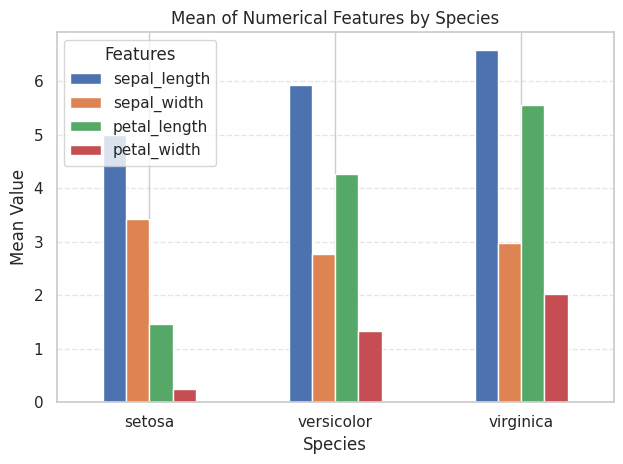

In [ ]:
species_mean.plot(kind='bar')

plt.title('Mean of Numerical Features by Species')
plt.xlabel('Species')
plt.ylabel('Mean Value')
plt.xticks(rotation=0)
plt.legend(title='Features')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

<Axes: xlabel='sepal_length', ylabel='Count'>

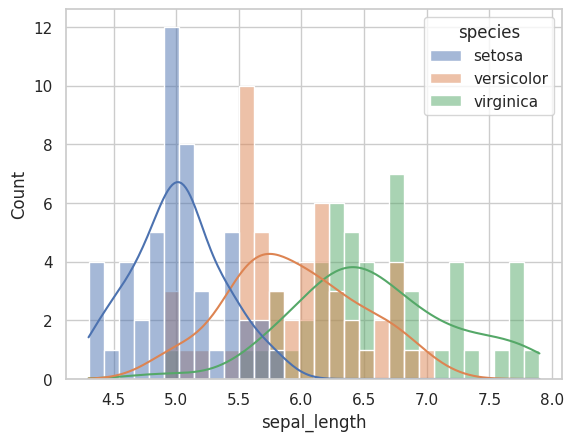

In [ ]:
sns.histplot(data=df, x='sepal_length', bins=30, hue='species', kde=True)

<Axes: xlabel='sepal_width', ylabel='Count'>

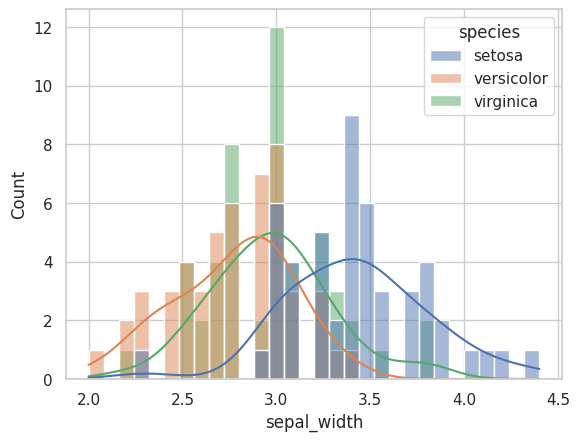

In [ ]:
sns.histplot(data=df, x='sepal_width', bins=30, kde=True, hue='species')

<Axes: xlabel='petal_length', ylabel='Count'>

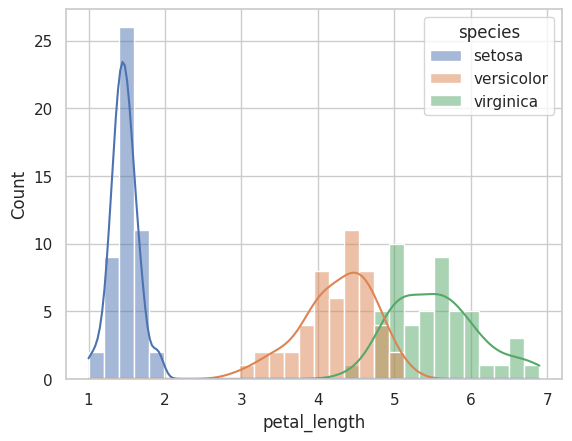

In [ ]:
sns.histplot(data=df, x='petal_length', bins=30, kde=True,hue='species')

<Axes: xlabel='petal_width', ylabel='Count'>

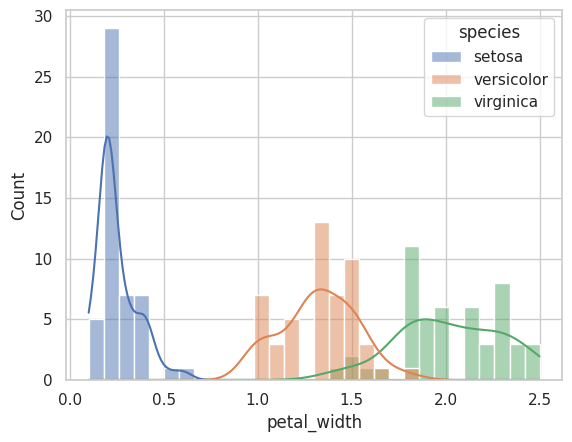

In [ ]:
sns.histplot(data=df, x='petal_width', bins=30, kde=True, hue='species')

<Axes: ylabel='sepal_length'>

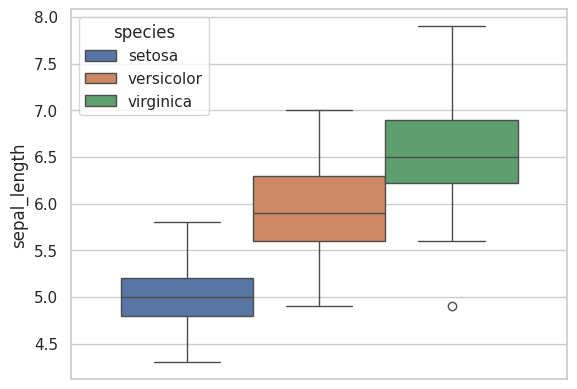

In [ ]:
sns.boxplot(data=df,y='sepal_length',hue='species')

<Axes: ylabel='sepal_width'>

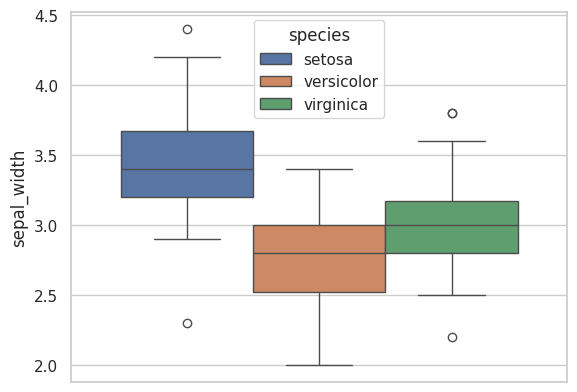

In [ ]:
sns.boxplot(data=df,y='sepal_width',hue='species')

<Axes: ylabel='petal_length'>

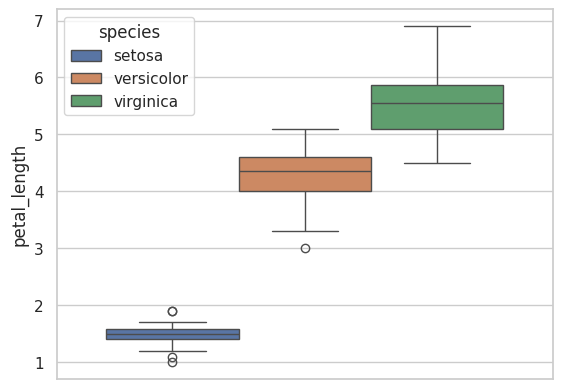

In [ ]:
sns.boxplot(data=df,y='petal_length',hue='species')

<Axes: ylabel='petal_width'>

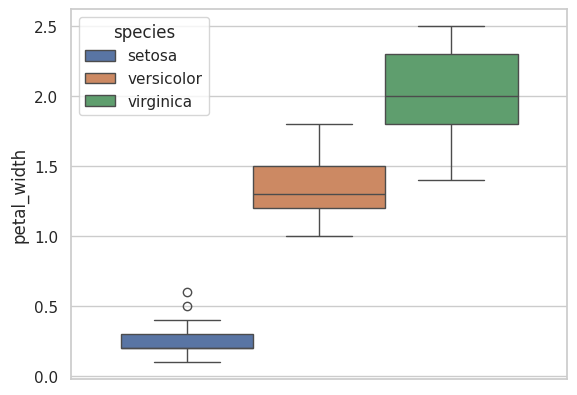

In [ ]:
sns.boxplot(data=df,y='petal_width',hue='species')

In [ ]:
# Select numerical features
#numeric_df = df[['sepal_length', 'sepal_width','petal_length', 'petal_width']]

numeric_df = df.drop('species', axis=1)

# Calculate correlation
correlation_matrix = numeric_df.corr()

print(correlation_matrix)

              sepal_length  sepal_width  petal_length  petal_width
sepal_length      1.000000    -0.117570      0.871754     0.817941
sepal_width      -0.117570     1.000000     -0.428440    -0.366126
petal_length      0.871754    -0.428440      1.000000     0.962865
petal_width       0.817941    -0.366126      0.962865     1.000000


<Axes: >

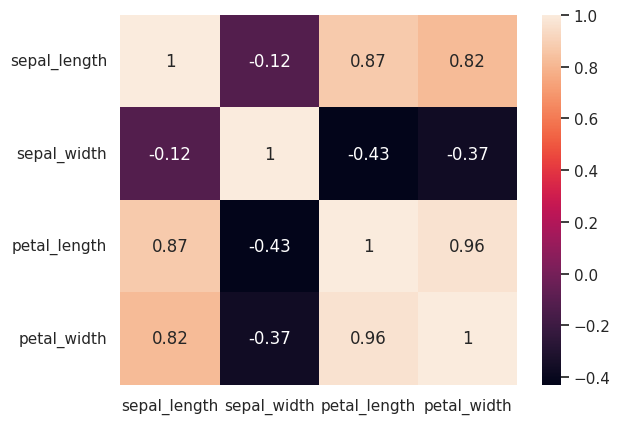

In [ ]:
sns.heatmap(correlation_matrix, annot=True)